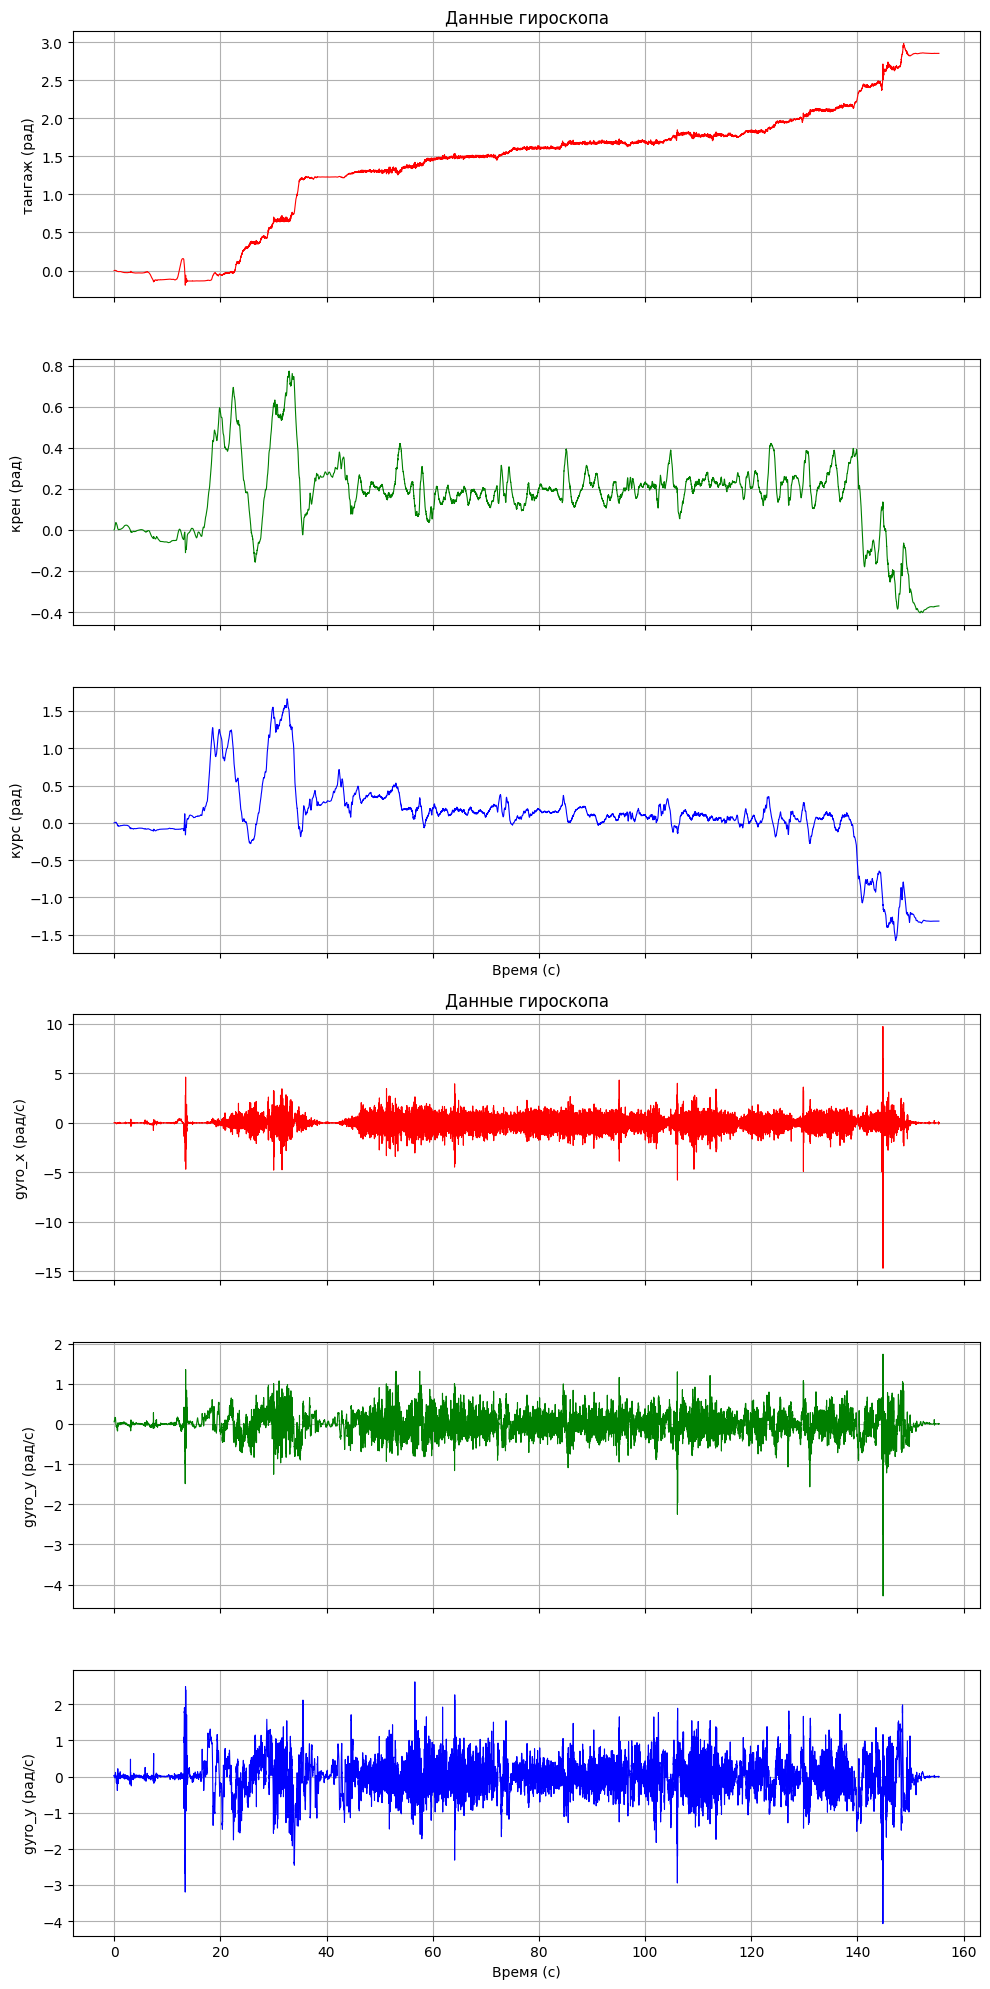

In [13]:
from matplotlib import pyplot as plt
import csv
from math import *
from scipy.integrate import quad, dblquad
import numpy as np
import random


def read_csv_gyro(fname):
    time = []
    x = []
    y = []
    z = []
    init = False
    t0 = 0
    with open(fname, newline = '') as csvfile:
        datareader = csv.reader(csvfile)
        for row in datareader:
            if (len(row)>=4):
                if init:
                    if t0 == 0:
                        t0 = float(row[0])
                    time.append((float(row[0])-t0)/10e8)
                    z.append(float(row[2]))
                    y.append(float(row[3]))
                    x.append(float(row[4]))
                else:
                    init=True
    return time, x, y, z

def integral(t, x0):
    x = [0]
    for i in range(1, len(t)):
        dt = t[i] - t[i-1]
        x.append(x[i-1] + x0[i]*dt)
    return x

def derivative(t, x0):
    x = [0]
    for i in range(1, len(t)):
        dt = t[i] - t[i-1]
        x.append((x0[i] - x0[i-1])/dt)
    return x
    

time, gyro_x, gyro_y, gyro_z = read_csv_gyro("C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\маленькое видео\\9-2026-10-03_13-22-24\\Gyroscope.csv")
#time, gyro_x, gyro_y, gyro_z = read_csv_gyro("C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\большое видео на 14 мин\\2026-10-03_12-49-46\\Gyroscope.csv")


heading = integral(time, gyro_z)
roll = integral(time, gyro_y)
pitch = integral(time, gyro_x)

fig, axs = plt.subplots(6, 1, figsize=(10, 20), sharex=True)

# График X
axs[0].plot(time, pitch, color='red', linewidth=0.8)
axs[0].set_ylabel('тангаж (рад)')
axs[0].grid(True)
axs[0].set_title('Данные гироскопа')

# График Y
axs[1].plot(time, roll, color='green', linewidth=0.8)
axs[1].set_ylabel('крен (рад)')
axs[1].grid(True)

# График Z
axs[2].plot(time, heading, color='blue', linewidth=0.8)
axs[2].set_ylabel('курс (рад)')
axs[2].set_xlabel('Время (с)')
axs[2].grid(True)

# График X
axs[3].plot(time, gyro_x, color='red', linewidth=0.8)
axs[3].set_ylabel('gyro_x (рад/с)')
axs[3].grid(True)
axs[3].set_title('Данные гироскопа')

# График Y
axs[4].plot(time, gyro_y, color='green', linewidth=0.8)
axs[4].set_ylabel('gyro_y (рад/с)')
axs[4].grid(True)

# График Z
axs[5].plot(time, gyro_z, color='blue', linewidth=0.8)
axs[5].set_ylabel('gyro_y (рад/с)')
axs[5].set_xlabel('Время (с)')
axs[5].grid(True)

# Автоматически подгоняем отступы, чтобы подписи не перекрывались
plt.tight_layout()

# Отображаем все графики в одном окне
plt.show()

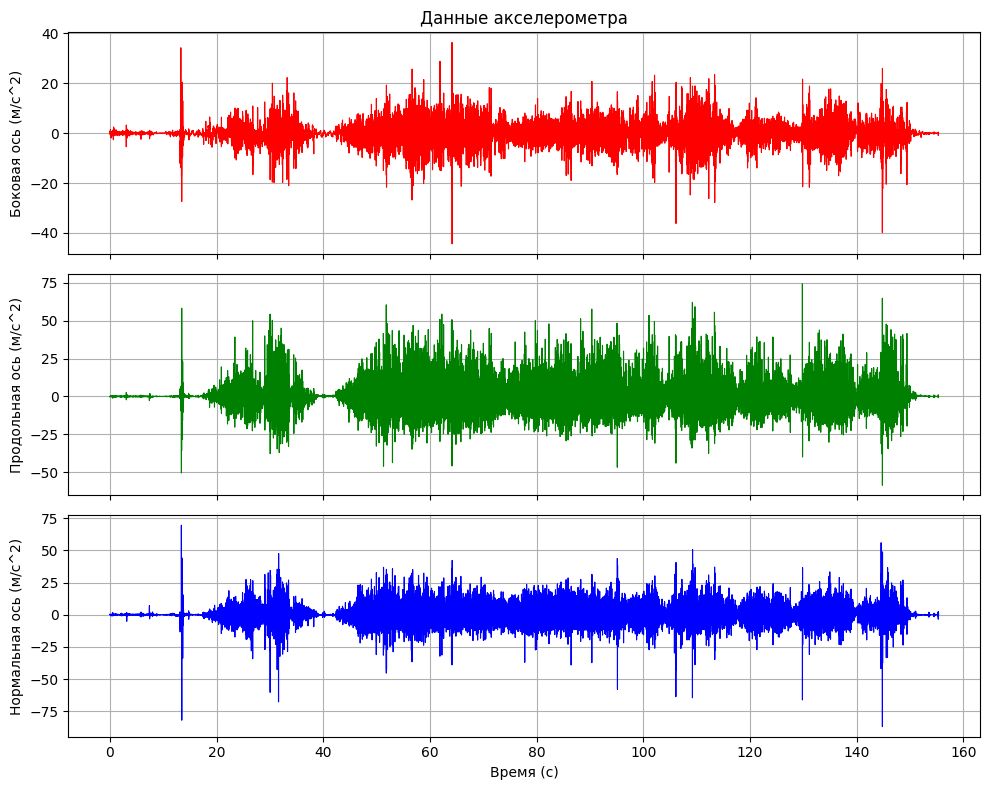

15999
15999


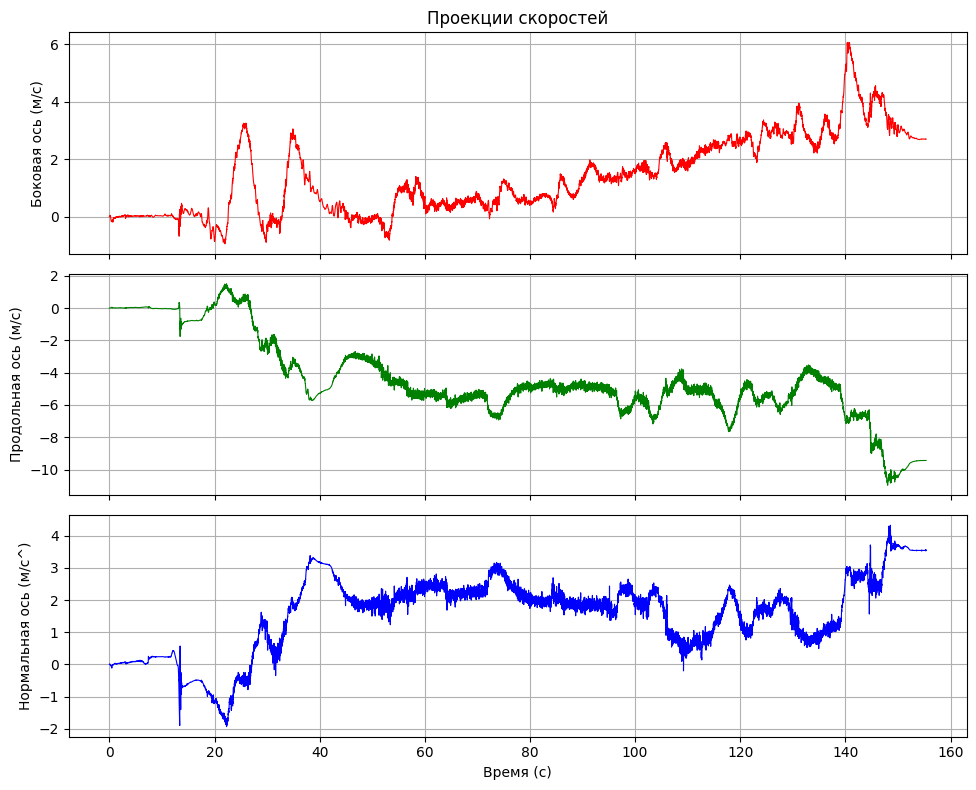

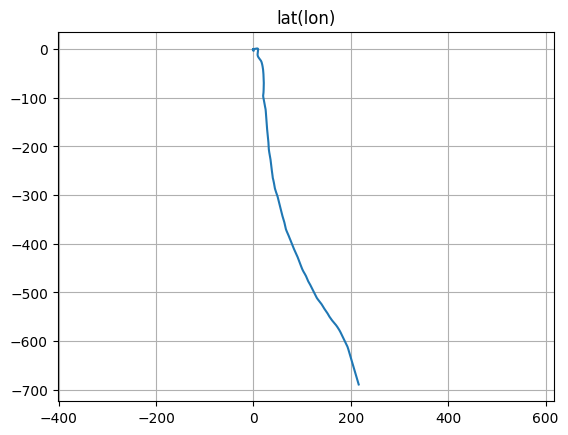

C:\Users\o4enn\AppData\Local\Temp\ipykernel_19664\1270046011.py:97: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


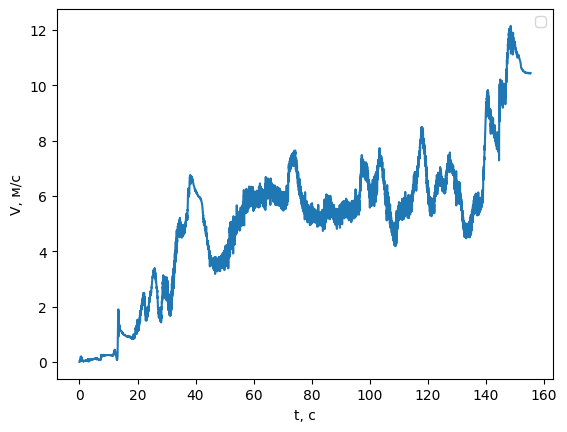

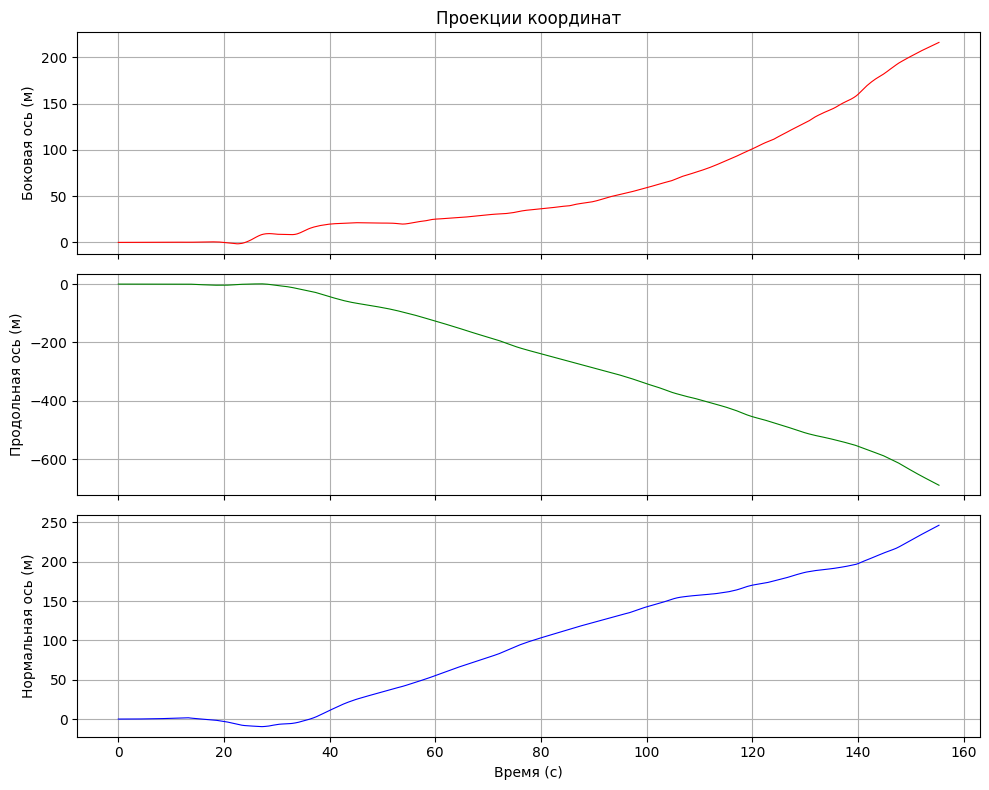

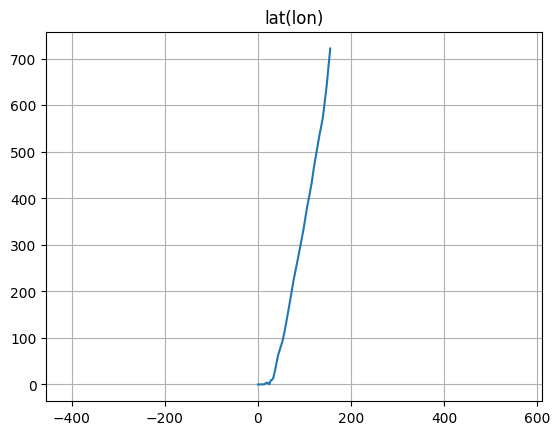

In [14]:
def read_csv_acc(fname):
    time = []
    x = []
    y = []
    z = []
    init = False
    t0 = 0
    with open(fname, newline = '') as csvfile:
        datareader = csv.reader(csvfile)
        for row in datareader:
            if (len(row)>=4):
                if init:
                    if t0 == 0:
                        t0 = float(row[0])
                    time.append((float(row[0])-t0)/10e8)
                    z.append(float(row[2]))
                    y.append(float(row[3]))
                    x.append(float(row[4]))
                else:
                    init=True
    return time, x, y, z

time, acc_x, acc_y, acc_z = read_csv_acc('C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\маленькое видео\\9-2026-10-03_13-22-24\\Accelerometer.csv')
#time, acc_x, acc_y, acc_z = read_csv_acc("C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\большое видео на 14 мин\\2026-10-03_12-49-46\\Accelerometer.csv")

fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# График X
axs[0].plot(time, acc_x, color='red', linewidth=0.8)
axs[0].set_ylabel('Боковая ось (м/с^2)')
axs[0].grid(True)
axs[0].set_title('Данные акселерометра')

# График Y
axs[1].plot(time, acc_y, color='green', linewidth=0.8)
axs[1].set_ylabel('Продольная ось (м/с^2)')
axs[1].grid(True)

# График Z
axs[2].plot(time, acc_z, color='blue', linewidth=0.8)
axs[2].set_ylabel('Нормальная ось (м/с^2)')
axs[2].set_xlabel('Время (с)')
axs[2].grid(True)

# Автоматически подгоняем отступы, чтобы подписи не перекрывались
plt.tight_layout()

# Отображаем все графики в одном окне
plt.show()

V_prod = integral(time, acc_y)
V_bok = integral(time, acc_x)
V_norm = integral(time, acc_z)

print(len(time))
print(len(V_bok))

fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
# График X
axs[0].plot(time, V_bok, color='red', linewidth=0.8)
axs[0].set_ylabel('Боковая ось (м/с)')
axs[0].grid(True)
axs[0].set_title('Проекции скоростей')

# График Y
axs[1].plot(time, V_prod, color='green', linewidth=0.8)
axs[1].set_ylabel('Продольная ось (м/с)')
axs[1].grid(True)

# График Z
axs[2].plot(time, V_norm, color='blue', linewidth=0.8)
axs[2].set_ylabel('Нормальная ось (м/с^)')
axs[2].set_xlabel('Время (с)')
axs[2].grid(True)

# Автоматически подгоняем отступы, чтобы подписи не перекрывались
plt.tight_layout()

# Отображаем все графики в одном окне
plt.show()

lon = integral(time, V_bok)
lat = integral(time, V_prod)
plt.plot(lon, lat)
plt.grid(True)
plt.title('lat(lon)')
plt.axis('equal')
plt.show()

V = []
for i in range(len(V_bok)):
    V.append(sqrt(V_bok[i]**2+V_norm[i]**2+V_prod[i]**2))

plt.plot(time, V)
plt.xlabel('t, c')
plt.ylabel('V, м/с')
plt.legend()
plt.show()

y = integral(time, V_prod)
x = integral(time, V_bok)
z = integral(time, V_norm)

summm = []
for i in range(len(V_bok)):
    summm.append(sqrt(x[i]**2+y[i]**2))

fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
# График X
axs[0].plot(time, x, color='red', linewidth=0.8)
axs[0].set_ylabel('Боковая ось (м)')
axs[0].grid(True)
axs[0].set_title('Проекции координат')

# График Y
axs[1].plot(time, y, color='green', linewidth=0.8)
axs[1].set_ylabel('Продольная ось (м)')
axs[1].grid(True)

# График Z
axs[2].plot(time, z, color='blue', linewidth=0.8)
axs[2].set_ylabel('Нормальная ось (м)')
axs[2].set_xlabel('Время (с)')
axs[2].grid(True)

# Автоматически подгоняем отступы, чтобы подписи не перекрывались
plt.tight_layout()

# Отображаем все графики в одном окне
plt.show()

plt.plot(time, summm)
plt.grid(True)
plt.title('lat(lon)')
plt.axis('equal')
plt.show()

Средняя горизонтальная ошибка ГНСС: 0.60 м
Средняя вертикальная ошибка ГНСС: 1.79 м
Средняя ошибка скорости ГНСС: 1.62 м/с
63
15999


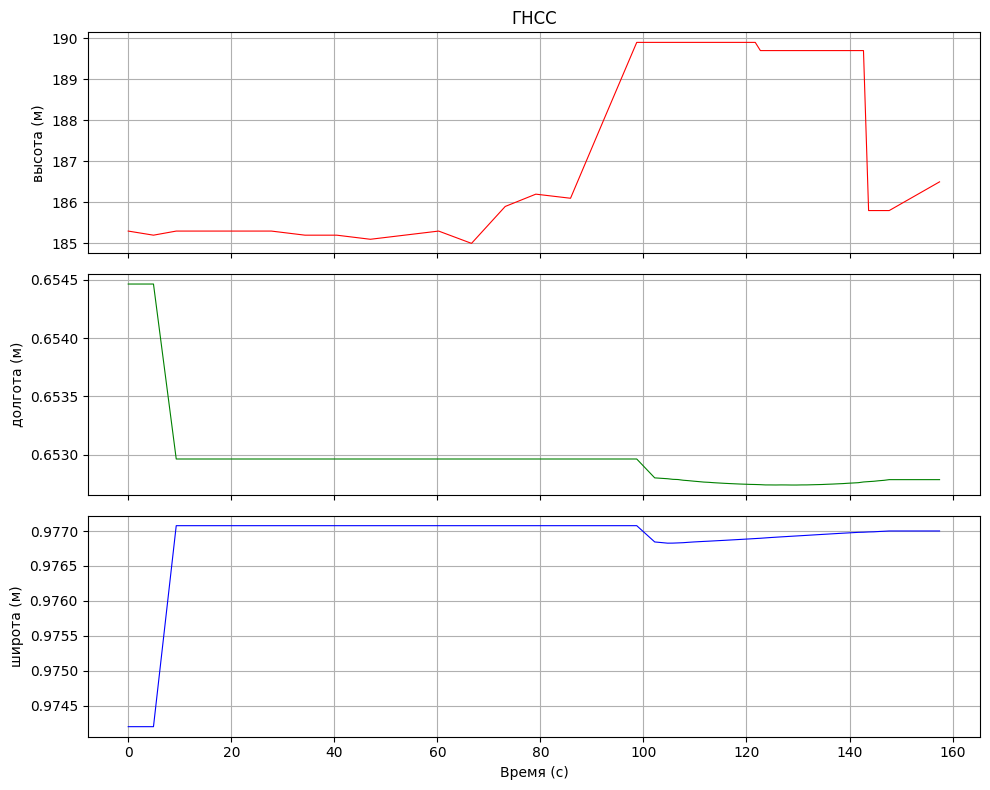

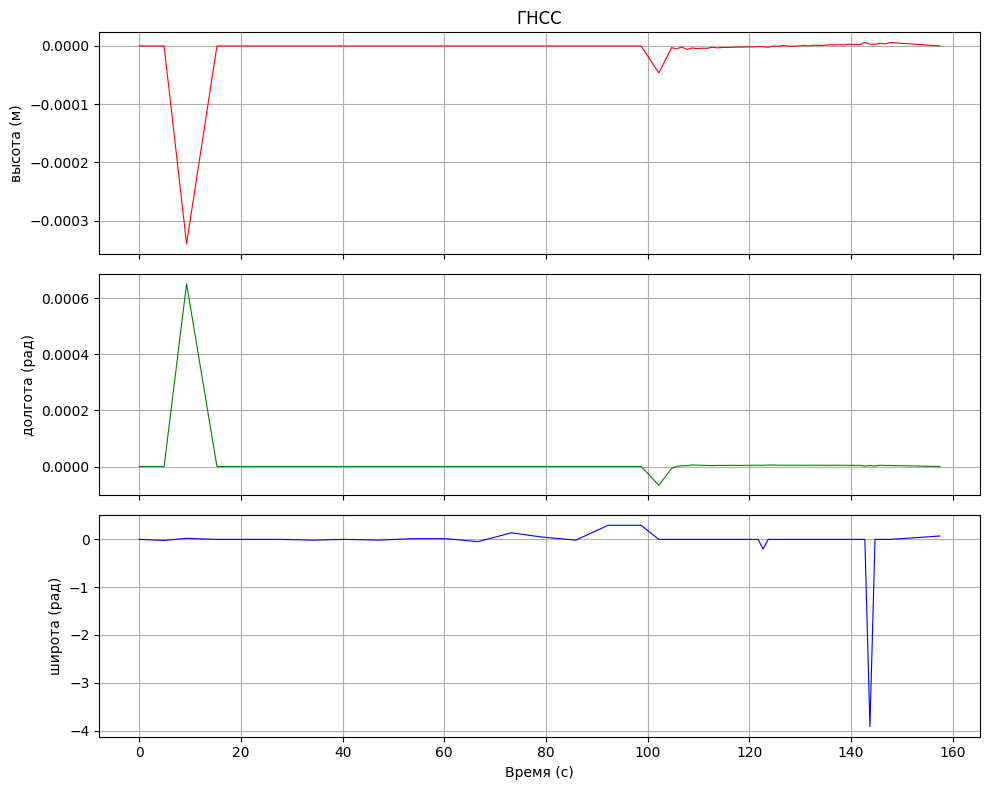

In [15]:
'''def read_csv_gnss(fname):
    time = []
    altitude = []
    longitude = []
    latitude = []
    init = False
    t0 = 0
    with open(fname, newline = '') as csvfile:
        datareader = csv.reader(csvfile)
        for row in datareader:
            if (len(row)>=4):
                if init:
                    if t0 == 0:
                        t0 = float(row[0])
                    time.append((float(row[0])-t0)/10e8)
                    altitude.append(float(row[8]))
                    longitude.append(float(row[9]) *pi/180)
                    latitude.append(float(row[10]) *pi/180)
                else:
                    init=True
    return time, altitude, longitude, latitude
'''
def read_csv_gnss(fname):
    time = []
    altitude = []
    longitude = []
    latitude = []
    hor_acc = []   # <-- Добавляем список для горизонтальной точности
    ver_acc = []   # <-- Добавляем список для вертикальной точности
    spd_acc = []   # <-- Добавляем список для точности скорости
    
    init = False
    t0 = 0
    with open(fname, newline = '') as csvfile:
        datareader = csv.reader(csvfile)
        for row in datareader:
            if (len(row) >= 11): # Убедимся, что столбцов достаточно
                if init:
                    if t0 == 0:
                        t0 = float(row[0])
                    time.append((float(row[0])-t0)/10e8)
                    
                    # Читаем координаты
                    altitude.append(float(row[8]))
                    longitude.append(float(row[9]) *pi/180)
                    latitude.append(float(row[10]) *pi/180)
                    
                    # Читаем оценки точности (ошибки)
                    hor_acc.append(float(row[5]) *pi/180) # horizontalAccuracy
                    ver_acc.append(float(row[4])) # verticalAccuracy
                    spd_acc.append(float(row[3])) # speedAccuracy
                else:
                    init=True
    return time, altitude, longitude, latitude, hor_acc, ver_acc, spd_acc

time_gnss, altitude, longitude, latitude, hor_acc, ver_acc, spd_acc = read_csv_gnss('C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\маленькое видео\\9-2026-10-03_13-22-24\\Location.csv')
#time_gnss, altitude, longitude, latitude = read_csv_gnss("C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\большое видео на 14 мин\\2026-10-03_12-49-46\\Location.csv")

sigma_horiz = np.median(hor_acc) 
sigma_vert = np.median(ver_acc)
sigma_speed = np.median(spd_acc)

print(f"Средняя горизонтальная ошибка ГНСС: {sigma_horiz:.2f} м")
print(f"Средняя вертикальная ошибка ГНСС: {sigma_vert:.2f} м")
print(f"Средняя ошибка скорости ГНСС: {sigma_speed:.2f} м/с")
print(len(hor_acc))

print(len(time))

fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# График X
axs[0].plot(time_gnss, altitude, color='red', linewidth=0.8)
axs[0].set_ylabel('высота (м)')
axs[0].grid(True)
axs[0].set_title('ГНСС')

# График Y
axs[1].plot(time_gnss, longitude, color='green', linewidth=0.8)
axs[1].set_ylabel('долгота (м)')
axs[1].grid(True)

# График Z
axs[2].plot(time_gnss, latitude, color='blue', linewidth=0.8)
axs[2].set_ylabel('широта (м)')
axs[2].set_xlabel('Время (с)')
axs[2].grid(True)

# Автоматически подгоняем отступы, чтобы подписи не перекрывались
plt.tight_layout()

# Отображаем все графики в одном окне
plt.show()

'''Эта хрень вычисляется по данным от ГНСС-модуля'''
Vh_gnss = derivative(time_gnss, altitude)
Ve_gnss = derivative(time_gnss, longitude)
Vn_gnss = derivative(time_gnss, latitude)
fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# График X
axs[0].plot(time_gnss, Ve_gnss, color='red', linewidth=0.8)
axs[0].set_ylabel('высота (м)')
axs[0].grid(True)
axs[0].set_title('ГНСС')

# График Y
axs[1].plot(time_gnss, Vn_gnss, color='green', linewidth=0.8)
axs[1].set_ylabel('долгота (рад)')
axs[1].grid(True)

# График Z
axs[2].plot(time_gnss, Vh_gnss, color='blue', linewidth=0.8)
axs[2].set_ylabel('широта (рад)')
axs[2].set_xlabel('Время (с)')
axs[2].grid(True)

# Автоматически подгоняем отступы, чтобы подписи не перекрывались
plt.tight_layout()

# Отображаем все графики в одном окне
plt.show()

In [16]:
dr_grs = 15*pi/180/3600 #rad/s
shum_grs = dr_grs*0.05*(random.random()-0.5)*2 #rad/s
dr_acc = 10**(-1) #m/s^2
shum_acc = dr_acc*0.05*(random.random()-0.5)*2 #m/s^2

x1, x2 = sigma_horiz, sigma_horiz #m - ошибки определения координат БИНС, связанные с ошибками определения долготы и широты, соответственно
x3, x4 = sigma_speed, sigma_speed #m/s – ошибки в определении скорости изменения координат БИНС, связанные с ошибками определения восточной и северной составляющими путевой скорости (проекции путевой скорости на оси НЗСК)
gamma = 0.1*pi/180 #rad
alfa, betta = 0.01*pi/180, 0.01*pi/180 #rad


speed_GNSS_sh = 0.1 #m/s

a = 6378245 #м, большая полуось в эллипсоиде Красовского
b = 6356863 #м, малая полуось в эллипсоиде Красовского
eks = 0.00335232987
w_sh = 1.53809*10**(-6)
g = 9.80665

R_e = 6371000 #Средний радиус Земли в метрах

#w_sh = sqrt(g / R_e)

#Начальная погрешность определения местоположения
X1 = [x1]
X2 = [x2]
X3 = [x3]
X4 = [x4]
time_model = [0.4]
#p1_list = [a * (1 - eks**2)/(sqrt(1 - eks**2 * sin(latitude[0])**2))**3 + altitude[0]]
#p2_list = [a/sqrt(1 - eks**2 * sin(latitude[0])**2) + altitude[0]]

'''Это из курсача Петухова
koord_GNSS_sh1 = 8/(p2_list[0]*cos(latitude[0])) #m
koord_GNSS_sh2 = 8/p1_list[0] #m
Это из курсача Петухова'''

X_0 = np.array([x1, x2, x3, x4, alfa, betta, gamma, dr_grs, dr_grs, dr_grs, dr_acc, dr_acc, dr_acc])
X = X_0

'''Для модели измерений'''
#V = np.array([sigma_horiz, sigma_horiz, sigma_speed, sigma_speed]) #Вектор шумов системы 

'''Для ОФК'''


#print(f'R = {R}')
E = np.eye(13)

X_kr_pred = X_0

P_pred = np.diag([x1**2, x2**2, x3**2, x4**2, alfa**2, betta**2, gamma**2, dr_grs**2, dr_grs**2, dr_grs**2, dr_acc**2, dr_acc**2, dr_acc**2])

X_kr_list1 = [X_0[0]]
X_kr_list2 = [X_0[1]]
X_kr_list3 = [X_0[2]]
X_kr_list4 = [X_0[3]]
X_kr_list_alfa = [X_0[4]]
X_kr_list_beta = [X_0[5]]
X_kr_list_gamma = [X_0[6]]

min_SKO1 = [-3*sqrt(P_pred[0][0])]
min_SKO2 = [-3*sqrt(P_pred[1][1])]
min_SKO3 = [-3*sqrt(P_pred[2][2])]
min_SKO4 = [-3*sqrt(P_pred[3][3])]
min_SKO5 = [-3*sqrt(P_pred[4][4])]
min_SKO6 = [-3*sqrt(P_pred[5][5])]
min_SKO7 = [-3*sqrt(P_pred[6][6])]

SKO1 = [3*sqrt(P_pred[0][0])]
SKO2 = [3*sqrt(P_pred[1][1])]
SKO3 = [3*sqrt(P_pred[2][2])]
SKO4 = [3*sqrt(P_pred[3][3])]
SKO5 = [3*sqrt(P_pred[4][4])]
SKO6 = [3*sqrt(P_pred[5][5])]
SKO7 = [3*sqrt(P_pred[6][6])]

In [17]:
Vh = V_prod
Ve = V_bok
Vn = V_norm

# Начальные значения БИНС (берем из первого тика ГНСС или заданы вручную)
lat_ins = latitude[0]   # Широта БИНС (в радианах или градусах - главное привести к одному виду с ГНСС)
lon_ins = longitude[0]  # Долгота БИНС
Ve_ins = 0.0            # Восточная скорость БИНС (м/с)
Vn_ins = 0.0            # Северная скорость БИНС (м/с)
Vh_ins = 0.0            # Вертикальная скорость БИНС (м/с)

i_gnss = 1

for t in range(1, len(time)):
    shag_vrem = time[t] - time[t-1]
    #shag_vrem = 0.1
    time_model.append(time[t])
    
    #Матрица перехода из связанной СК в нормальную
    c11 = cos(heading[t])*cos(pitch[t])
    c12 = sin(heading[t])*sin(roll[t]) - cos(heading[t])*sin(pitch[t])*cos(roll[t])
    c13 = sin(heading[t])*cos(roll[t]) + cos(heading[t])*sin(pitch[t])*sin(roll[t])
    c21 = sin(pitch[t])
    c22 = cos(pitch[t])*cos(roll[t])
    c23 = -cos(pitch[t])*sin(roll[t])
    c31 = -sin(heading[t])*cos(pitch[t])
    c32 = cos(heading[t])*sin(roll[t]) + sin(heading[t])*sin(pitch[t])*cos(roll[t])
    c33 = cos(heading[t])*cos(roll[t]) - sin(heading[t])*sin(pitch[t])*sin(roll[t])\
    
    C = np.array([[c11, c12, c13], 
                  [c21, c22, c23], 
                  [c31, c32, c33]])
    
    acc = np.array([acc_x[t], acc_y[t], acc_z[t]])
    n = C @ acc

    gyro = np.array([gyro_y[t], gyro_x[t], gyro_z[t]])
    Omega = C @ gyro

    p1 = a * (1 - eks**2) / (sqrt(1 - eks**2 * sin(lat_ins)**2))**3 + altitude[i_gnss]
    p2 = a / sqrt(1 - eks**2 * sin(lat_ins)**2) + altitude[i_gnss]

    #Моделируем БИНС, а не просто интегрируем
    Ve_ins = Ve_ins + acc[0] * shag_vrem
    Vn_ins = Vn_ins + acc[1] * shag_vrem
    Vh_ins = Vh_ins + acc[2] * shag_vrem

    lat_ins = lat_ins + (Vn_ins / p1) * shag_vrem
    lon_ins = lon_ins + (Ve_ins / (p2 * cos(lat_ins))) * shag_vrem

    #Синхролнизация ГНСС и БИНС
    if (t % 250 == 0) and (i_gnss < len(time_gnss) - 1):
        i_gnss += 1

    delta_lyamda_BINS = X[0]/(p2 * cos(lat_ins)) #ошибка определения долготы
    delta_fi_BINS = X[1]/p1 #ошибка определения широты

    #print(f'omega = {Omega}')
    
    delta_Ve_BINS = X[2] - (Vh[t]/p2 + Omega[0]*tan(lat_ins))*X[0] - Omega[1]*X[1] #ошибка определения восточной проекции путевой скорости
    delta_VN_BINS = X[3] - Vh[t]/p1 * X[0] #ошибка определения северной проекции путевой скорости

    '''print(delta_lyamda)
    print(delta_fi)
    print(delta_Ve)
    print(delta_VN)
    print('-------')'''
  
    #Если будут ошибки, перепроверить тут

    F = np.array([
        [0,     0,     1, 0,    0,  0,    0,        0,      0,      0,          0,      0,      0],
        [0,     0,     0, 1,    0,  0,    0,        0,      0,      0,          0,      0,      0],
        [-w_sh, 0,     0, 0,    0, n[2],  0,        0,      0,      0,      C[0][0], C[0][1], C[0][2]],
        [0,     -w_sh, 0, 0, -n[2], 0,   n[0],      0,      0,      0,      C[1][0], C[1][1], C[1][2]],
        [0,     0,     0, 0,    0,  0,     0,   C[0][0], C[0][1], C[0][2],      0,      0,      0],
        [0,     0,     0, 0,    0,  0,     0,   C[1][0], C[1][1], C[1][2],      0,      0,      0],
        [0,     0,     0, 0,    0,  0,     0,   C[2][0], C[2][1], C[2][2],      0,      0,      0],
        [0,     0,     0, 0,    0,  0,     0,       0,      0,      0,          0,      0,      0],
        [0,     0,     0, 0,    0,  0,     0,       0,      0,      0,          0,      0,      0],
        [0,     0,     0, 0,    0,  0,     0,       0,      0,      0,          0,      0,      0],
        [0,     0,     0, 0,    0,  0,     0,       0,      0,      0,          0,      0,      0],
        [0,     0,     0, 0,    0,  0,     0,       0,      0,      0,          0,      0,      0],
        [0,     0,     0, 0,    0,  0,     0,       0,      0,      0,          0,      0,      0]
        ])
    
    W = np.array([shum_grs, shum_grs, shum_grs, shum_acc, shum_acc, shum_acc])
    V = np.array([hor_acc[i_gnss], hor_acc[i_gnss], spd_acc[i_gnss], spd_acc[i_gnss]])

    G = np.array([
        [   0,      0,      0,          0,      0,      0    ],
        [   0,      0,      0,          0,      0,      0    ],
        [   0,      0,      0,      C[0][0], C[0][1], C[0][2]],
        [   0,      0,      0,      C[1][0], C[1][1], C[1][2]],
        [C[0][0], C[0][1], C[0][2],     0,      0,      0    ],
        [C[1][0], C[1][1], C[1][2],     0,      0,      0    ],
        [C[2][0], C[2][1], C[2][2],     0,      0,      0    ],
        [   0,      0,      0,          0,      0,      0    ],
        [   0,      0,      0,          0,      0,      0    ],
        [   0,      0,      0,          0,      0,      0    ],
        [   0,      0,      0,          0,      0,      0    ],
        [   0,      0,      0,          0,      0,      0    ],
        [   0,      0,      0,          0,      0,      0    ]
        ])
    
    Xtoch = F @ X + G @ W #Нашли вектор Х с точкой, теперь нужно проинтегрировать Эйлером и записать результаты в списки
    #print (Xtoch)
    #print(X)
    X = X + Xtoch * shag_vrem
    X1.append(X[0].tolist() - X_0[0])
    X2.append(X[1].tolist() - X_0[1])
    X3.append(X[2].tolist() - X_0[2])
    X4.append(X[3].tolist() - X_0[3])

    '''lyamda_BINS = X1[t] / (p2*cos(lat_ins))
    fi_BINS = X2[t] / p1
    Ve_BINS = X3[t]
    Vn_BINS = X4[t]'''

    '''lyamda_GNSS = (longitude[i_gnss])
    fi_GNSS = (latitude[i_gnss]) 
    Ve_GNSS = (Ve_gnss[i_gnss])
    Vn_GNSS = (Vn_gnss[i_gnss])'''

    '''if (t%295==0):
        Z_matr = np.array([lyamda_BINS-lyamda_GNSS, fi_BINS-fi_GNSS, Ve_BINS-Ve_GNSS, Vn_BINS-Vn_GNSS]) #Вектор измерений
    else:
        Z_matr = np.array([lyamda_BINS-0, fi_BINS-0, Ve_BINS-0, Vn_BINS-0]) #Вектор измерений'''

    #Формируем матрицу измерений Z
    delta_lat = (lat_ins - latitude[i_gnss])
    delta_lon = (lon_ins - longitude[i_gnss])
    delta_Ve = Ve_ins - Ve_gnss[i_gnss]
    delta_Vn = Vn_ins - Vn_gnss[i_gnss]

    '''delta_lat = (delta_fi_BINS - hor_acc[i_gnss])
    delta_lon = (delta_lyamda_BINS - hor_acc[i_gnss])
    delta_Ve = delta_Ve_BINS - Ve_gnss[i_gnss]
    delta_Vn = delta_VN_BINS - Vn_gnss[i_gnss]'''

    # Вектор измерений Z (в метрах и м/с)
    Z_matr = np.array([delta_lon, delta_lat, delta_Ve, delta_Vn])   

    #Вариант из курсача
    #Z_matr = np.array([lyamda_BINS-lyamda_GNSS, fi_BINS-fi_GNSS, Ve_BINS-Ve_GNSS, Vn_BINS-Vn_GNSS]) #Вектор измерений

    H = np.array([  #Матрица связи вектора состояния и вектора измерений
        [       1/(p2*cos(lat_ins)),                    0,    0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [               0,                             1/p1,  0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [-(Vh[i_gnss]/p2 + Omega[0]*tan(lat_ins)), -Omega[1], 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [             -Vh[i_gnss]/p1,                   0,    0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]
        ])
    
    '''АЛГОРИТM ОФК'''
    Ef_rus = E + F*shag_vrem
    Ge_rus = G*shag_vrem

    R = np.diag([(25/(p2*cos(lat_ins)))**2, (25/p1) **2, speed_GNSS_sh**2, speed_GNSS_sh**2]) #Матрица интенсивности шумов системы
    Q = np.diag([shum_grs**2, shum_grs**2, shum_grs**2, shum_acc**2, shum_acc**2, shum_acc**2]) #матрица интенсивности шумов системы

    S = Ef_rus @ P_pred @ Ef_rus.T + Ge_rus @ (Q) @ Ge_rus.T #Расчет априорной матрицы ковариации

    #Считаем Калмановские коэффициенты усиления

    K = S @ H.T @ np.linalg.inv(H @ S @ H.T + (R))

    P_new = (E - K @ H) @ S #Расчет апостериорной матрицы ковариации

    X_kr = Ef_rus @ X_kr_pred + K @ (Z_matr - H @ Ef_rus @ X_kr_pred)

    X_kr_list1.append(X_kr[0])
    X_kr_list2.append(X_kr[1])
    X_kr_list3.append(X_kr[2])
    X_kr_list4.append(X_kr[3])
    X_kr_list_alfa.append(X_kr[4])
    X_kr_list_beta.append(X_kr[5])
    X_kr_list_gamma.append(X_kr[6])
    SKO = np.diag([sqrt(P_pred[0][0]), sqrt(P_pred[1][1]), sqrt(P_pred[2][2]), sqrt(P_pred[3][3]), sqrt(P_pred[4][4]), sqrt(P_pred[5][5]), sqrt(P_pred[6][6]), 
               sqrt(P_pred[7][7]), sqrt(P_pred[8][8]), sqrt(P_pred[9][9]), sqrt(P_pred[10][10]), sqrt(P_pred[11][11]), sqrt(P_pred[12][12])])

    P_pred = P_new
    
    #print(SKO)
    X_kr_pred = X_kr

    min_SKO1.append(-3*SKO[0][0])
    min_SKO2.append(-3*SKO[1][1])
    min_SKO3.append(-3*SKO[2][2])
    min_SKO4.append(-3*SKO[3][3])
    min_SKO5.append(-3*SKO[4][4])
    min_SKO6.append(-3*SKO[5][5])
    min_SKO7.append(-3*SKO[6][6])

    SKO1.append(3*SKO[0][0])
    SKO2.append(3*SKO[1][1])
    SKO3.append(3*SKO[2][2])
    SKO4.append(3*SKO[3][3])
    SKO5.append(3*SKO[4][4])
    SKO6.append(3*SKO[5][5])
    SKO7.append(3*SKO[6][6])

print(SKO1[0])


1.8008656815233786


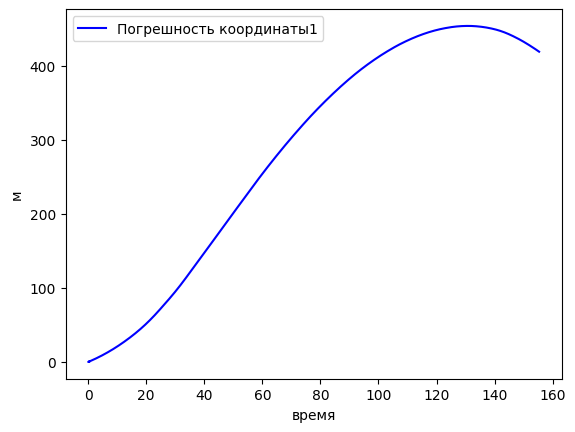

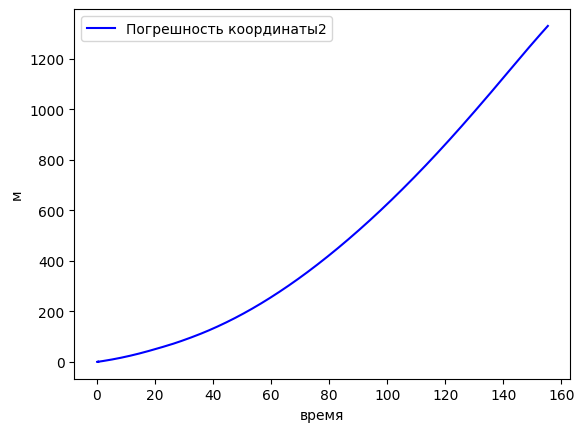

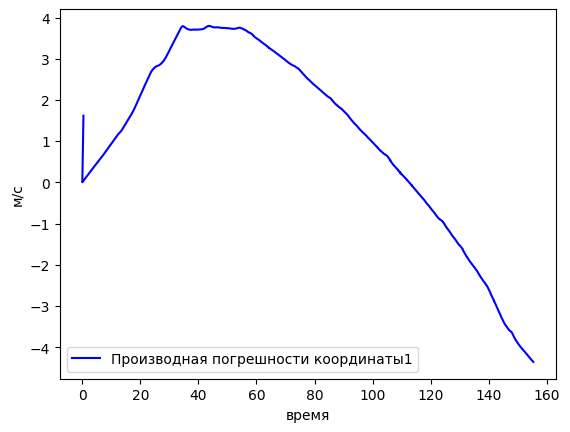

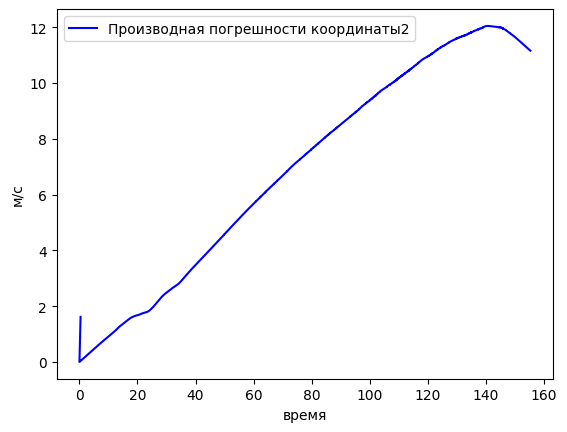

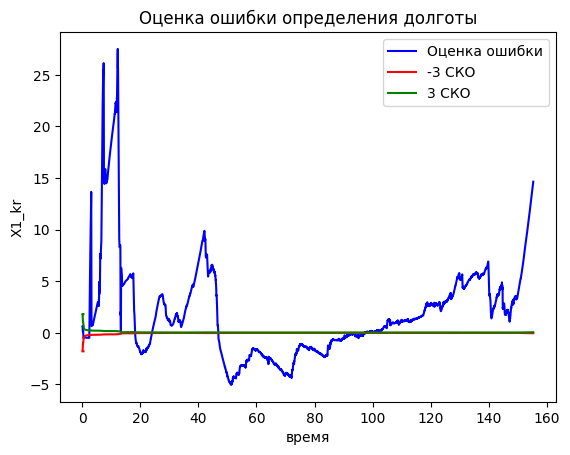

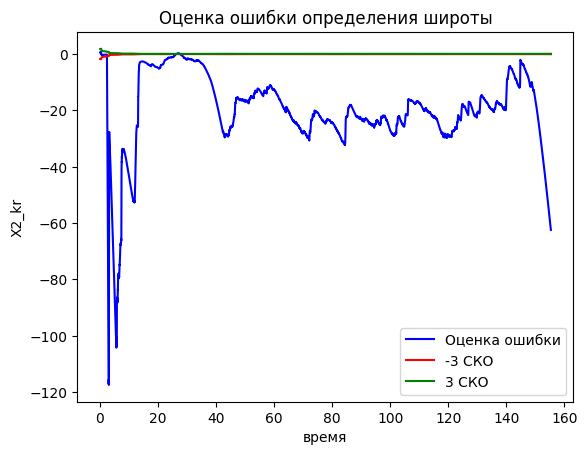

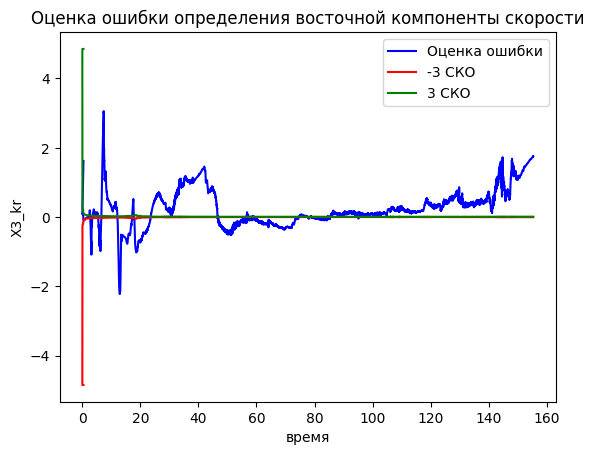

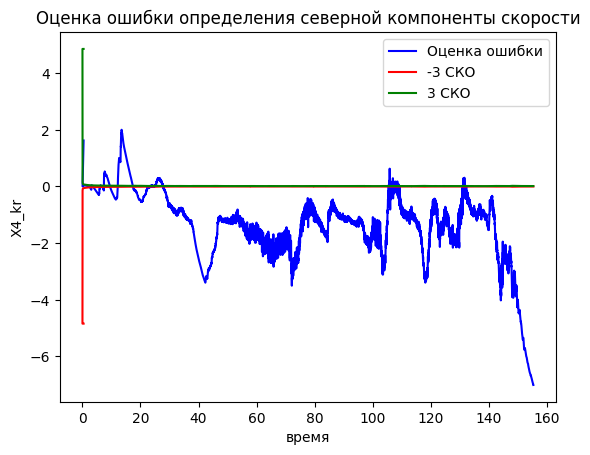

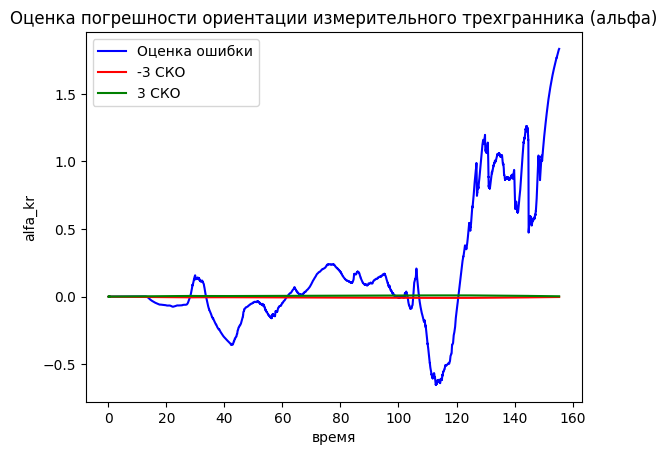

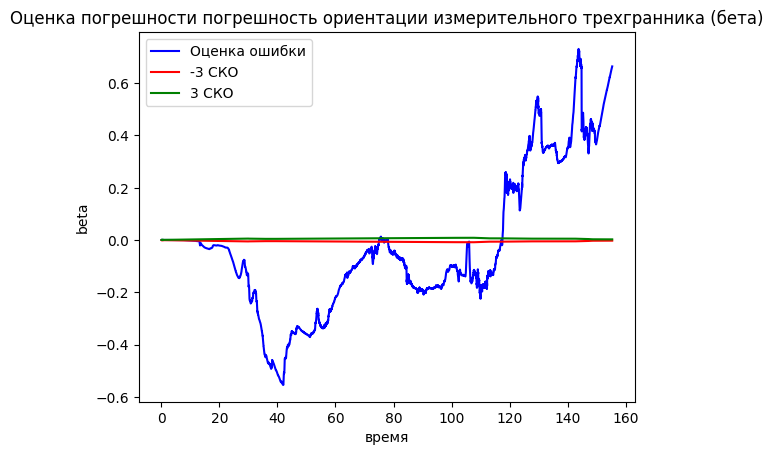

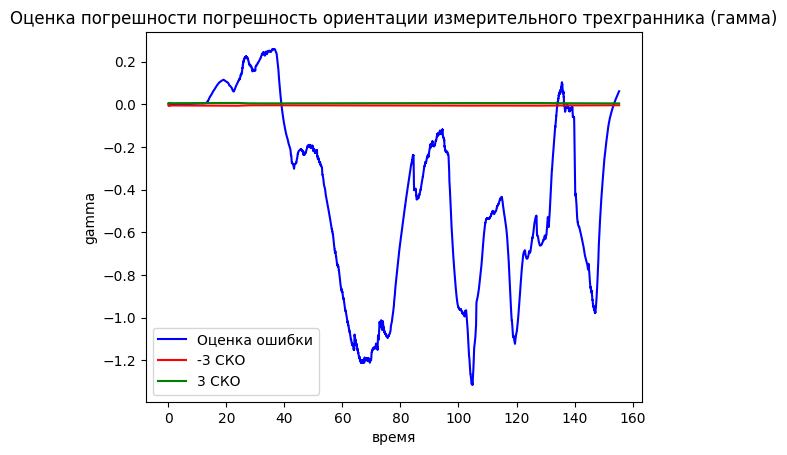

In [18]:

# Графики погрешностей
plt.plot(time_model, X1, c='b', label='Погрешность координаты1')
plt.xlabel('время')
plt.ylabel('м')
plt.legend() 
plt.show()

plt.plot(time_model, X2, c='b', label='Погрешность координаты2')
plt.xlabel('время')
plt.ylabel('м')
plt.legend()
plt.show()

plt.plot(time_model, X3, c='b', label='Производная погрешности координаты1')
plt.xlabel('время')
plt.ylabel('м/с')
plt.legend()
plt.show()

plt.plot(time_model, X4, c='b', label='Производная погрешности координаты2')
plt.xlabel('время')
plt.ylabel('м/с')
plt.legend()
plt.show()

'''Итоговые графики'''

plt.figure()
plt.plot(time_model, X_kr_list1, label='Оценка ошибки', c='b')
plt.plot(time_model, min_SKO1, label='-3 СКО', c='r')  # Добавляем метку для СКО
plt.plot(time_model, SKO1, label='3 СКО', c='g')  # Добавляем метку для СКО
plt.xlabel('время')
plt.ylabel('X1_kr')
plt.title('Оценка ошибки определения долготы')
plt.legend(loc='best')  # Автоматическое размещение легенды
plt.show()

plt.plot(time_model, X_kr_list2, label='Оценка ошибки', c='b')
plt.plot(time_model, min_SKO2, label='-3 СКО', c='r')
plt.plot(time_model, SKO2, label='3 СКО', c='g')  # Добавляем метку для СКО
plt.xlabel('время')
plt.ylabel('X2_kr')
plt.title('Оценка ошибки определения широты')
plt.legend()
plt.show()

plt.plot(time_model, X_kr_list3, label='Оценка ошибки', c='b')
plt.plot(time_model, min_SKO3, label='-3 СКО', c='r')
plt.plot(time_model, SKO3, label='3 СКО', c='g')  # Добавляем метку для СКО
plt.xlabel('время')
plt.ylabel('X3_kr')
plt.title('Оценка ошибки определения восточной компоненты скорости')
plt.legend()
plt.show()

plt.plot(time_model, X_kr_list4, label='Оценка ошибки', c='b')
plt.plot(time_model, min_SKO4, label='-3 СКО', c='r')
plt.plot(time_model, SKO4, label='3 СКО', c='g')  # Добавляем метку для СКО
plt.xlabel('время')
plt.ylabel('X4_kr')
plt.title('Оценка ошибки определения северной компоненты скорости')
plt.legend()
plt.show()

# Графики ориентации
plt.plot(time_model, X_kr_list_alfa, label='Оценка ошибки', c='b')
plt.plot(time_model, min_SKO5, label='-3 СКО', c='r')
plt.plot(time_model, SKO5, label='3 СКО', c='g')  # Добавляем метку для СКО
plt.xlabel('время')
plt.ylabel('alfa_kr')
plt.title('Оценка погрешности ориентации измерительного трехгранника (альфа)')
plt.legend()
plt.show()

plt.plot(time_model, X_kr_list_beta, label='Оценка ошибки', c='b')
plt.plot(time_model, min_SKO6, label='-3 СКО', c='r')
plt.plot(time_model, SKO6, label='3 СКО', c='g')  # Добавляем метку для СКО
plt.xlabel('время')
plt.ylabel('beta')
plt.title('Оценка погрешности погрешность ориентации измерительного трехгранника (бета)')
plt.legend()
plt.show()

plt.plot(time_model, X_kr_list_gamma, label='Оценка ошибки', c='b')
plt.plot(time_model, min_SKO7, label='-3 СКО', c='r')
plt.plot(time_model, SKO7, label='3 СКО', c='g')  # Добавляем метку для СКО
plt.xlabel('время')
plt.ylabel('gamma')
plt.title('Оценка погрешности погрешность ориентации измерительного трехгранника (гамма)')
plt.legend()
plt.show()


# Спутниковая система